# Machine Learning: Exercise session 06

In this exercise session we will focus on Logistic regression and decision trees.

In the first problem, we will consider the [ionosphere dataset](https://www.openml.org/d/59) and fit different logistic regression models.
The goal is to predict whether a given radar signal from the ionosphere is "good" or "bad" based on 34 predictors.

In the second problem, we will focus on decision trees.

In the third problem, we will derive the log-likelihood function for logistic regression.

**Note:** the third problem is theoretical and __not__ needed for the hand in.

## Problem 1

* Import the dataset `ionosphere.csv`, separate the predictors and the target variable and split it into training and test set. When you perform the splitting, set `random_state=12` and `test_size=151`.

In [48]:
from unicodedata import category

import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression

data = pd.read_csv('/Users/helianferraris/Desktop/Machine Learning/Exercise_06/ionosphere.csv')

X = data.iloc[:, :-1]
y = data.iloc[:, -1]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 151, random_state = 12)



In [49]:
print(X_train.shape) # (200, 34)
print(X_test.shape) # (151, 34)
print(y_train.value_counts())

# 351 rows total

(200, 34)
(151, 34)
class
g    123
b     77
Name: count, dtype: int64


* Define a `Pipeline` where you apply the `StandardScaler` and then fit a `LogisticRegression` with the following tuning parameters: `penalty="none"`, `solver="saga"`, `tol=0.1`, `random_state=10`. Call the pipeline `pipe_logistic`.

In [50]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipe_logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_reg", LogisticRegression(penalty = None, solver = 'saga', tol = 0.1, random_state= 10))
])




* Fit the pipeline to the training data and predict the accuracy on the training and test dataset.

In [51]:
pipe_logistic.fit(X_train, y_train)
print(f" Accuracy test {pipe_logistic.score(X_test, y_test)}")
print(f" Accuracy train {pipe_logistic.score(X_train, y_train)}")

 Accuracy test 0.8609271523178808
 Accuracy train 0.895


We now want to fit a logistic regression with the lasso penalty. To do that we need to choose the best regulatization parameter. 

* Define a `Kfold` object with 10 splits, and `random_state=919`. Remeber to shuffle the rows. Name the object `folds`.

In [52]:
from sklearn.model_selection import KFold

folds = KFold(n_splits=10 , shuffle=True, random_state=919)

* Define a `Pipeline` where you first apply the `StandardScaler` (name this step `"scaler"`) and then fit a `LogisticRegression` (name this step `"logistic"`) with the following tuning parameters: `C=1`, `penalty="l1"`, `solver="saga"`, `tol=0.1`, `random_state=10`. Name the pipeline `pipe_logistic_l1`. What is the role of `C`? How does it compare to the tuning parameter `alpha` from `Lasso`?

In [53]:
pipe_logistic_l1 = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(C=1,penalty = 'l1', solver = 'saga', tol = 0.1, random_state= 10))
])

* Define now a `GridSearchCV` object to perform the cross-validation over a grid of different values for `C`. Fill in the `??`.

_Hint_: Choose carefully your grid, by trying out different possibility and looking at the cross-validated accuracy plot (see below). Ideally, you want a grid around the values of `C` that are "interesting".

In [54]:
from sklearn.model_selection import GridSearchCV

# Define CV object
grid = 10 ** np.linspace(-2, 0.5, 100)
logistic_l1_cv = GridSearchCV(
    estimator=pipe_logistic_l1,
    param_grid={"logistic__C": grid},
    scoring="accuracy",
    cv=folds,
)

* Perform the cross-validation on the training data.

In [55]:
logistic_l1_cv.fit(X_train, y_train)



GridSearchCV(cv=KFold(n_splits=10, random_state=919, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('logistic',
                                        LogisticRegression(C=1, penalty='l1',
                                                           random_state=10,
                                                           solver='saga',
                                                           tol=0.1))]),
             param_grid={'logistic__C': array([0.01      , 0.0105987 , 0.01123324, 0.01190577, 0.01261857,
       0.01337404, 0.01417474, 0.01502338, 0.01592283, 0.01687612,
       0.017...
       0.58570208, 0.62076796, 0.65793322, 0.69732357, 0.7390722 ,
       0.78332032, 0.83021757, 0.87992254, 0.93260335, 0.98843814,
       1.04761575, 1.11033632, 1.17681195, 1.24726747, 1.32194115,
       1.40108553, 1.48496826, 1.57387304, 1.66810054, 1.76796941,
       1.87381742, 1.98600253, 2.10490414, 2.23092437, 2.36448941,
       2.50605097, 2.65608778, 2.81510728, 2.98364724, 3.16227766])},
             scoring='accuracy')

* Plot the results of the cross-validation by filling in the `??`.

_Note_: Notice that we want to compute the best model according to the __1-se rule__. To do that, we need to compute the standard error of the __mean__ cross-validated accuracy. This is obtained by dividing the standard deviations by the square root of $K = 10$ (i.e., number of folds).

In [56]:
cv_res = logistic_l1_cv
cv_res.cv_results_.keys()

dict_keys(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_logistic__C', 'params', 'split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score', 'split4_test_score', 'split5_test_score', 'split6_test_score', 'split7_test_score', 'split8_test_score', 'split9_test_score', 'mean_test_score', 'std_test_score', 'rank_test_score'])

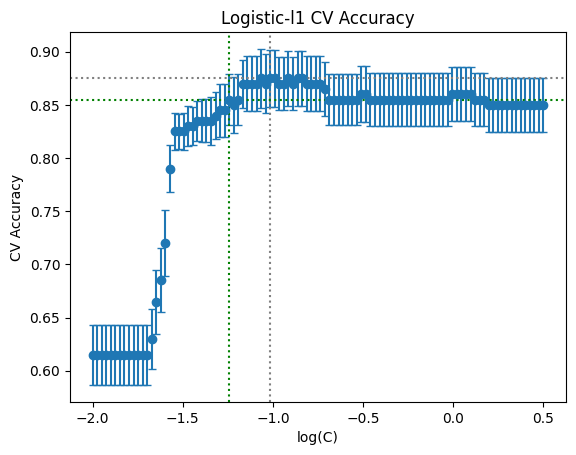

0.05722367659350217
0.09657139052966049


In [63]:
import matplotlib.pyplot as plt

# Plot results of cross-validation

mean_scores = cv_res.cv_results_['mean_test_score']
se_scores = cv_res.cv_results_['std_test_score'] / np.sqrt(10) # ! very important to divide by sqrt(# folds)
params = cv_res.cv_results_['param_logistic__C'].data

best_index = np.argmax(mean_scores)

one_se_best_param = np.min(
    grid[mean_scores >= mean_scores[best_index] - se_scores[best_index]]
)

one_se_score = mean_scores[grid == one_se_best_param][0]

# just for reference, we also plot the parameter that maximizes the cross-validated accuracy
best_param = cv_res.best_params_["logistic__C"] 
best_score = cv_res.best_score_

plt.errorbar(x=np.log10(grid), y=mean_scores, yerr=se_scores, fmt="o", capsize=3)

plt.axvline(
    np.log10(best_param), ls="dotted", color="grey"
)  # vertical line at the parameter value yielding highest accuracy
plt.axhline(
    best_score, ls="dotted", color="grey"
)  # horizontal line at highest accuracy
plt.axvline(
    np.log10(one_se_best_param), ls="dotted", color="green"
)  # vertical line at the parameter corresponding to 1-se
plt.axhline(
    one_se_score, ls="dotted", color="green"
)  # horizontal line at corresponding to 1-se parameter

plt.title("Logistic-l1 CV Accuracy")
plt.xlabel("log(C)")
plt.ylabel("CV Accuracy")
plt.show()

print(one_se_best_param)
print(best_param)

* Finally, refit the __1-se rule__ model to the whole training dataset, and compute the accuracy on the training and test dataset.

In [73]:
log_best = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(C=one_se_best_param,penalty = 'l1', solver = 'saga', tol = 0.1, random_state= 10))
])

log_best.fit(X_train, y_train)

print(f" Accuracy test: {log_best.score(X_test, y_test)}")
print(f" Accuracy train: {log_best.score(X_train, y_train)}")

np.sum(log_best.named_steps["logistic"].coef_ == 0) #29

 Accuracy test: 0.8211920529801324
 Accuracy train: 0.855


np.int64(29)

* Does this model perform better than the unregularized logistic regression? What are the advantages of this model?


How big is the drop? On 151 test rows, 0.861 vs 0.821 is 130 vs 124 correct predictions, so 6 observations. A test accuracy of about 0.85 on 151 points has a standard error of roughly 0.03 (√(0.85·0.15/151)), so a 0.04 gap is not strong evidence that one model is truly worse.

A second factor: our unregularized model was fitted with tol=0.1, which stops the solver early. That already acts as a mild implicit shrinkage, so it was less overfit than a fully converged model would be. This leaves less room for the lasso to improve things.

So the answer to “does it perform better?” is: no, not in accuracy, and the difference is small compared with the noise.

**Advantages of the lasso model:**

Simpler model, fewer predictors. The l1 penalty sets some coefficients to exactly zero, so it does variable selection as part of the fit. This is what the unregularized model can’t do.
Easier to interpret. We can say which of the 34 radar measurements actually matter.

Cheaper and more robust in practice. Fewer inputs to collect and less room to fit noise, which matters most when we have many predictors and few rows (here 34 against 200).

The accuracy cost is small and was chosen on purpose. The 1-se rule trades up to one standard error of accuracy for simplicity.

## Problem 2

In [67]:
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, train_test_split, GridSearchCV

### 2.0 Data import and Cleaning

Import the "Heart" dataset, containing demographic and medical informations about a list of patients. Drop `NA` values, convert the categorical variables into the desired pandas type: "category", and perform any other necessary data cleaning.

In [89]:
heart_dt = pd.read_csv('/Users/helianferraris/Desktop/Machine Learning/Exercise_06/Heart_ISL.csv', index_col=0)

heart_dt = heart_dt.dropna() # removes rows that contain NA

heart_dt['ChestPain'] = heart_dt['ChestPain'].astype('category')
#heart_dt['ChestPain'].dtype
heart_dt['Thal'] = heart_dt['Thal'].astype('category')
heart_dt['AHD'] = heart_dt['AHD'].astype('category')

heart_dt

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,asymptomatic,140,241,0,0,123,1,0.2,2,0.0,reversable,Yes
299,45,1,typical,110,264,0,0,132,0,1.2,2,0.0,reversable,Yes
300,68,1,asymptomatic,144,193,1,0,141,0,3.4,2,2.0,reversable,Yes
301,57,1,asymptomatic,130,131,0,0,115,1,1.2,2,1.0,reversable,Yes


The response variable that we will try to predict is "AHD", that indicates whether the patient has a heart disease.

Now split the data into the features `X` and the response `y`.

As, sadly, trees in sklearn do not handle categorical features directly, transform `X`'s categorical variables into "dummies". This can be achieved either with panda's `pd.get_dummies(<data>, drop_first=True)` or sklearn's `OneHotEncoder`. Make sure that you keep X in dataframe format, and keep feature/column names.

In [100]:
target_name = 'AHD'
X = heart_dt.drop(target_name, axis=1)
y = heart_dt[target_name]

X = pd.get_dummies(X, drop_first=True)



(pandas.core.frame.DataFrame,
 Index(['Age', 'Sex', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng',
        'Oldpeak', 'Slope', 'Ca', 'ChestPain_nonanginal',
        'ChestPain_nontypical', 'ChestPain_typical', 'Thal_normal',
        'Thal_reversable'],
       dtype='object'))

Split the data into train and test. Set random_state=40 and leave 20% of the data out for the test set.

In [103]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .2, random_state = 40)

print(X.shape)
print(X.columns)
print(X_train.shape)
print(X_test.shape)

(297, 16)
Index(['Age', 'Sex', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng',
       'Oldpeak', 'Slope', 'Ca', 'ChestPain_nonanginal',
       'ChestPain_nontypical', 'ChestPain_typical', 'Thal_normal',
       'Thal_reversable'],
      dtype='object')
(237, 16)
(60, 16)


### 2.1 Unpruned tree

In [104]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

Begin by fitting a (unpruned) classification tree to the training data, in order to predict whether each patient potentially has AHD, based on his available demographic and medical information. Use either the Gini index or the entropy as a splitting criterion, as you prefer.

In [111]:
tree_unpruned = DecisionTreeClassifier(criterion='entropy', random_state = 40, min_samples_leaf=1, ccp_alpha=0) # here min_samples_leaf and alpha are at their default value so calling them is optional

tree_unpruned.fit(X_train, y_train)

DecisionTreeClassifier(ccp_alpha=0, criterion='entropy', random_state=40)

Now plot the tree using sklearn's `plot_tree` function

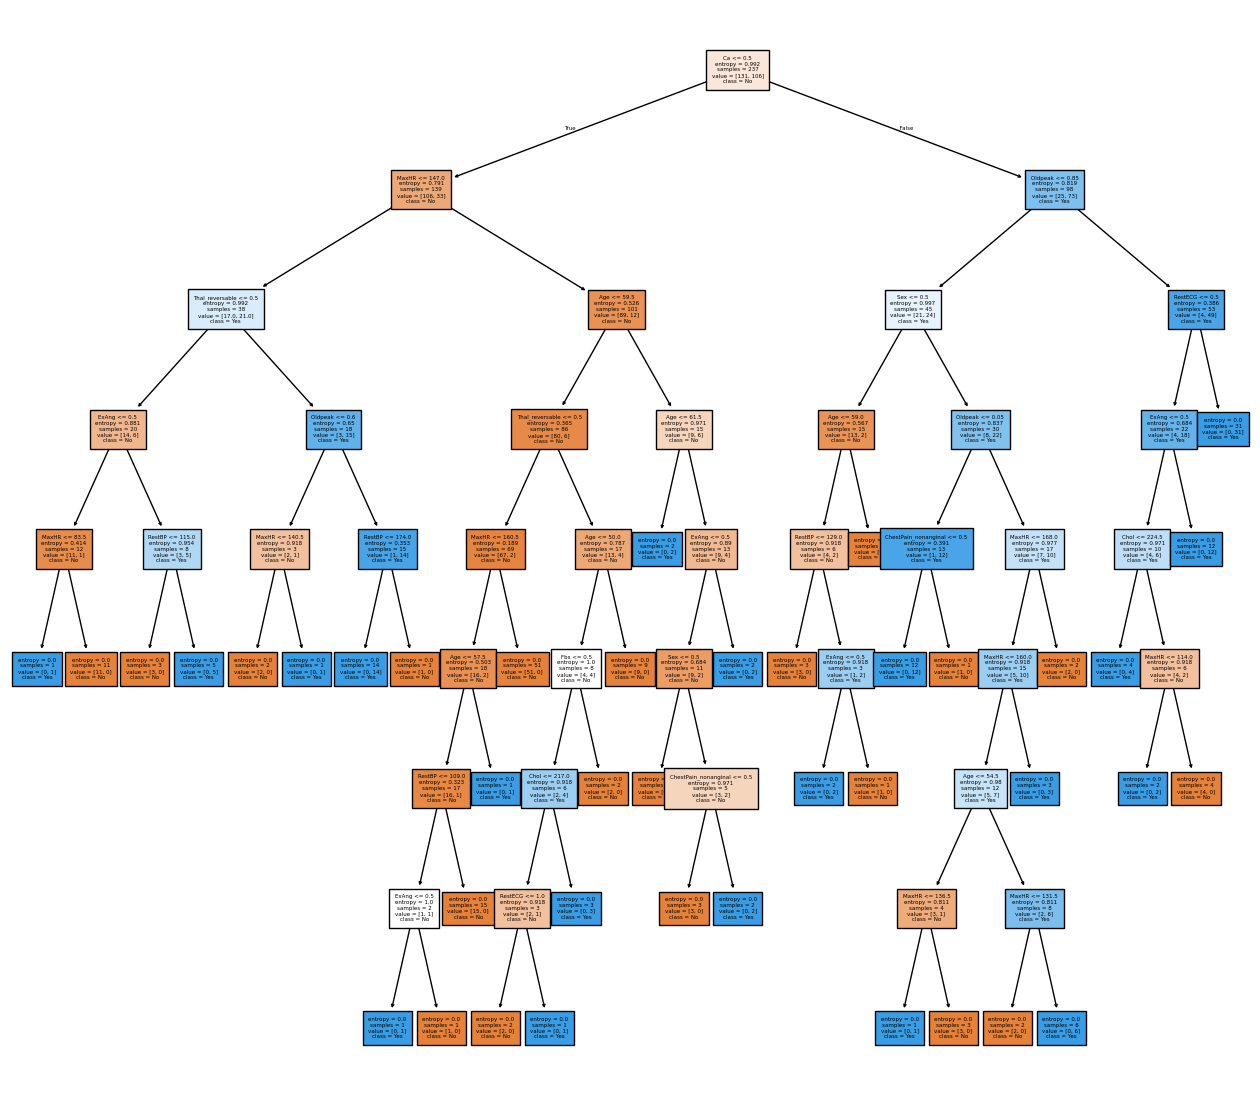

In [122]:
plt.figure(figsize=(16,14))
plot_tree(tree_unpruned, feature_names=X.columns, class_names=tree_unpruned.classes_, filled=True, fontsize=4)
plt.show()

Could you use only this image to predict the "AHD" variable for the observations left out in the test set?

Yes, the tree can be used for prediction from the image alone, by following the splits from the root to a leaf and taking the majority class there. However, this tree is overfit (train 1.0, test 0.717), so its predictions will generalize poorly.

Now check the model's training and test accuracy (or score). What do you observe and why ?

In [119]:
# Accuracies:

print(f' Train Accuracy: {tree_unpruned.score(X_train, y_train)}')
print(f' Test Accuracy: {tree_unpruned.score(X_test, y_test)}')

 Train Accuracy: 1.0
 Test Accuracy: 0.7166666666666667


### 2.2. Cost-complexity pruning

Remember that the flexibility of a decision tree can be tuned by pruning it via cost-complexity pruning.

Use cross-validation to select the best cost-complexity hyper-parameter $\alpha$ value. Then, plot the tree coresponding to the best $\alpha$ value.

In [132]:
path = tree_unpruned.cost_complexity_pruning_path(X_train, y_train)

print(path.ccp_alphas)
print(len(path.ccp_alphas))
print(min(path.ccp_alphas))
print(max(path.ccp_alphas))

[0.         0.00843882 0.01125176 0.011624   0.011624   0.01260704
 0.01369246 0.01410442 0.01471252 0.01507081 0.01536314 0.01688423
 0.01789688 0.0188724  0.02048419 0.02095275 0.02180282 0.02252886
 0.02282766 0.02670889 0.0302132  0.0353143  0.04750531 0.06317866
 0.08056114 0.1894429 ]
26
0.0
0.18944289635891076


In [133]:

# Define CV object
tree_cv = GridSearchCV(
    estimator=DecisionTreeClassifier(criterion='entropy', random_state = 40),
    param_grid={"ccp_alpha": path.ccp_alphas},
    scoring="accuracy",
    cv=folds,
)

In [141]:
tree_cv.fit(X_train, y_train)

print(f' Best alpha: {tree_cv.best_params_}')
print(f' CV Accuracy: {tree_cv.best_score_}')

 Best alpha: {'ccp_alpha': np.float64(0.026708894052679847)}
 CV Accuracy: 0.7894927536231884


In [136]:
print(f' Train Accuracy: {tree_cv.best_estimator_.score(X_train, y_train)}')
print(f' Test Accuracy: {tree_cv.best_estimator_.score(X_test, y_test)}')

 Train Accuracy: 0.8523206751054853
 Test Accuracy: 0.75


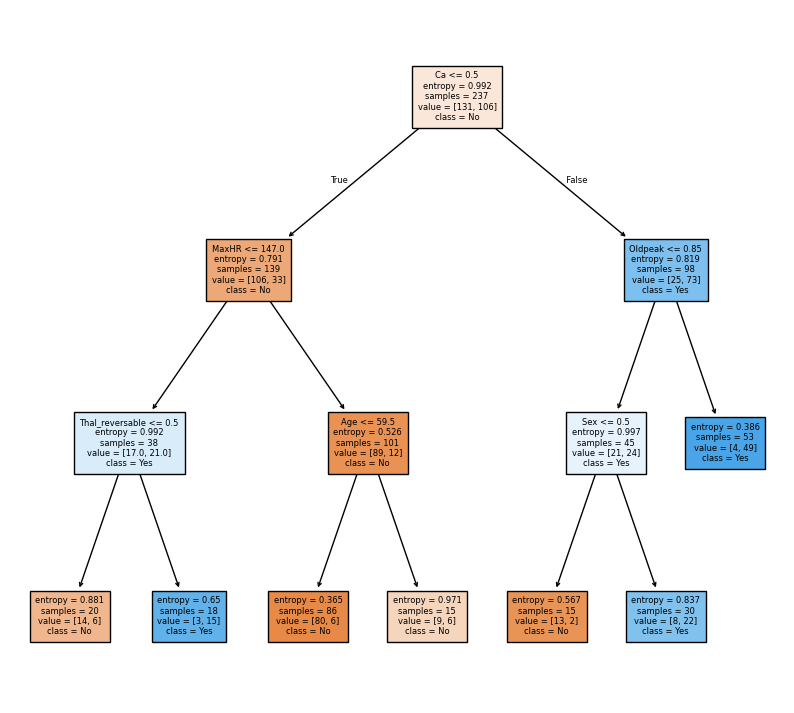

In [145]:
plt.figure(figsize=(10,9))
plot_tree(tree_cv.best_estimator_, feature_names=X.columns, class_names=tree_cv.best_estimator_.classes_, filled=True, fontsize=6)
plt.show()

## Problem 3 (not to hand in)

Suppose we have independent observations $(x_1,y_1),\dots, (x_n,y_n)$ from $(X,Y)$ with $x_i \in \mathbb R^p$, and $y_i \in \{0,1\}$,  $i = 1, \dots, n$.
Further assume that the conditional distribution of $Y$ given $X= x$ is Bernoulli with success probability denoted as:
  $$ \mathbb P(Y = 1 \mid X = x) = 1 - \mathbb P(Y = 0 \mid X = x) = \sigma(x^\top \beta),$$
where $\sigma: \mathbb R \to [0, 1]$, and
  $$
  \sigma(a) = \dfrac{e^{a}}{1 + e^{a}}, \quad a\in \mathbb R.
$$
Show that the log-likelihood of the parameter vector $\beta\in\mathbb R^p$ is
  $$\ell(\beta) = \sum_{i=1}^n y_i x_i^\top \beta - \log(1 + e^{x_i^\top \beta}).$$